In [2]:
import itertools
import lsst.afw.math as afwMath
from lsst.afw.math import binImage
import lsst.afw.image as afwImage
from lsst.daf.butler import Butler
from lsst import geom
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
import lsst.summit.utils.plotting as splot


In [3]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

In [4]:
def fitPlane(image, order=1):
    '''
    Function to fit a 1st order Chebyshev polynomial to a binned image

    Parameters
    ----------
    image : `lsst.afw.image._image.ImageF`
        FFP image
    order : `int`
        Order of polynomial to fit

    Returns
    -------
    bkgdImage : `lsst.afw.image._image.ImageF`
        Chebyshev model of image
    '''
    # Hard code fit parameters for the notebook
    undersampleStyle = "INCREASE_NXNYSAMPLE"
    statsCtrl = afwMath.StatisticsControl()
    statsCtrl.setNanSafe(True)

    statsFlag = afwMath.stringToStatisticsProperty("MEAN")
    statsCtrl.setNumSigmaClip(1)
    statsCtrl.setNumIter(1)

    width = image.getWidth()
    height = image.getHeight()

    bctrl = afwMath.BackgroundControl(width, height, statsCtrl, statsFlag)
    bctrl.setUndersampleStyle(undersampleStyle)

    bkgd = afwMath.makeBackground(image, bctrl)
    bkgd.getStatsImage().variance = afwImage.ImageF(np.sqrt(bkgd.getStatsImage().image.array))

    actrl = afwMath.ApproximateControl(afwMath.ApproximateControl.CHEBYSHEV, order, order, True)
    undersampleStyle = afwMath.stringToUndersampleStyle(undersampleStyle)

    approx = bkgd.getApproximate(actrl, undersampleStyle)
    bkgdImage = approx.getImage()

    return bkgdImage

In [5]:
# First two are nightlyValidation17, so need to be re-constructed
# Last two are nightlyValidation18, which are still around
visits = [2026010400145]

In [6]:
repo = "embargo"
# butler = Butler("embargo", collections=["LSSTCam/runs/nightlyValidation","LSSTCam/raw/all"], instrument="LSSTCam")

butler = Butler(config=repo)

In [7]:
coll = "LSSTCam/runs/nightlyValidation"
# coll=["u/ataranto/mono_flats"]#,"LSSTCam/runs/nightlyValidation","LSSTCam/runs/DRP/20250501_20250609/w_2025_26/DM-51580", "LSSTCam/runs/DRP/20250420_20250521/w_2025_21/DM-51076","LSSTCam/runs/DRP/20250415_20250422/d_2025_04_23/DM-50409"]


In [8]:
binning = 8
badMaskNames = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]

detects = range(0,189)
bad = [ 122]
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "visit": visits[0], "detector": i}
    if i in bad:
        continue
    else:
        try:
            im = butler.get("preliminary_visit_image_background", dataId=dataId, collections=coll)
            # bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)
            # msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
            # im.getMaskedImage().image.array[msk] = np.nan  # Try removing detections &c.
            ids.append(i)
            # pIsrImsBinned.append(binImage(im.getMaskedImage(), binning)) #original
            pIsrImsBinned.append(binImage(im.getImage(), binning))
        except:
            continue

100%|██████████| 189/189 [01:27<00:00,  2.16it/s]


In [9]:
# camera = butler.get("camera", instrument="LSSTCam", collections="LSSTCam/calib/DM-50716/unbounded")
from lsst.summit.utils.utils import getCameraFromInstrumentName

camera = getCameraFromInstrumentName("LSSTCam")


In [10]:
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)
pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
pIsrMosaic.array[pIsrMosaic.array < 0] = np.nan

nan


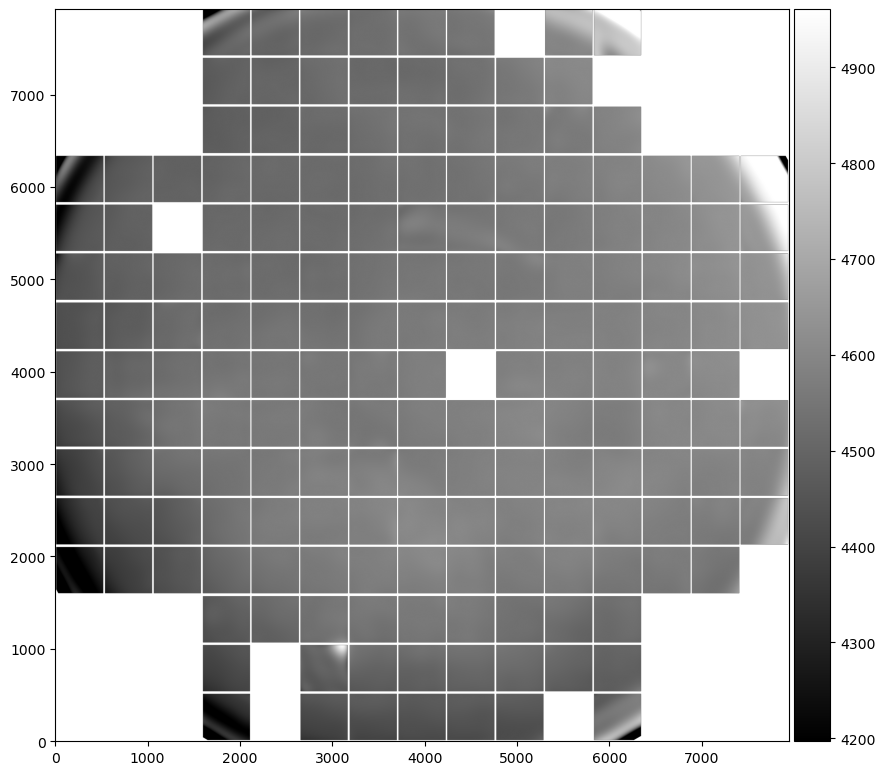

In [11]:
splot.plot(pIsrMosaic.array)
print(pIsrMosaic.array.mean())
# pIsrMosaic.writeFits("%d-flat-500nm.fits" % (visits[0]))

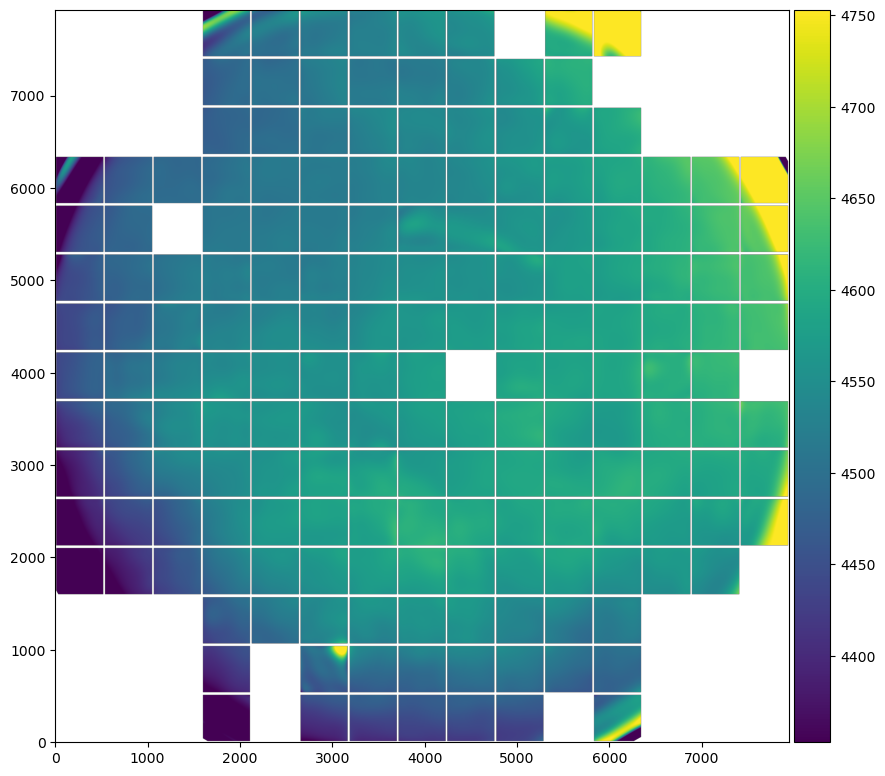

In [12]:
med = np.nanmedian(pIsrMosaic.array)
fig, ax = plt.subplots(1, figsize=(10, 10))
cb = ax.imshow(pIsrMosaic.array, vmin=med-200, vmax=med+200, origin="lower")
colorbar(cb)

# pIsrMosaic.writeFits("%d-sculptur.fits" % (visits[0]))

In [13]:
# Mask out the vignetted region before fitting
xCen, yCen = (pIsrMosaic.array.shape[0]/2, pIsrMosaic.array.shape[1]/2)
rad = (pIsrMosaic.array.shape[0] + pIsrMosaic.array.shape[1])/ 4  # Roughly the vignetted region radius
x = np.arange(1, pIsrMosaic.array.shape[1]+1)
y = x.reshape(-1, 1)
r = np.sqrt((x - xCen)**2 + (y - yCen)**2)
vignet = r >= rad

vignet = vignet[1:, :]

In [14]:
clone = pIsrMosaic.clone()
clone.array[vignet] = np.nan

IndexError: boolean index did not match indexed array along axis 0; size of axis is 7927 but size of corresponding boolean axis is 7938

In [ ]:
# First fit, ignoring the vignetted region
bkgd = fitPlane(clone, 1)

In [ ]:
# Now mask out bright residual peaks and fit again
want = (pIsrMosaic.array - bkgd.array) >= 5
clone.array[want] = np.nan
bkgd = fitPlane(clone, 2)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(pIsrMosaic.array, origin="lower", vmin=med-200, vmax=med+200)
ax[1].imshow(bkgd.array, origin="lower")
cb = ax[2].imshow(pIsrMosaic.array - bkgd.array, vmin=-50, vmax=50, origin="lower")
colorbar(cb)

In [18]:
bgSub = pIsrMosaic.clone()
bgSub.array -= bkgd.array
# bgSub.writeFits("%d-chopstick.fits" % (visits[0]))

In [19]:
# Examination of above images shows feature is ~40--50 cts above local background
bg = (-22.6393 - 9.09778)/2  # Local background is over-subtracted
surfBri = 110.87 - bg  # Counts -- if binImage uses the mean, this is /px, not /superpixel
nSuperPix = 26588  # Total number of pixels in the DS9 polygon, 64 x 64 px superpixels
totFlux = surfBri * (nSuperPix * 64**2)

In [ ]:
print("Surface brightness of feature: %.3f cts/px" % (surfBri))
print("Number of pixels: %d * (64*64) = %d px" %(nSuperPix, nSuperPix * 64**2))
print("Total flux = %.3f * %d = %3.f cts" % (surfBri, nSuperPix * 64**2, totFlux))

#### Now do the other one that's available

In [ ]:
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "exposure": visits[3], "detector": i}
    if i in bad:
        continue
    else:
        im = butler.get("post_isr_image", dataId=dataId, collections=coll)
        bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)
        msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
        im.getMaskedImage().image.array[msk] = np.nan  # Try removing detections &c.
        ids.append(i)
        pIsrImsBinned.append(binImage(im.getMaskedImage(), binning))

In [ ]:
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)
pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData

In [ ]:
med = np.nanmedian(pIsrMosaic.array)
fig, ax = plt.subplots(1, figsize=(10, 10))
cb = ax.imshow(pIsrMosaic.array, vmin=med-200, vmax=med+200, origin="lower")
colorbar(cb)

In [ ]:
clone = pIsrMosaic.clone()
clone.array[vignet] = np.nan

In [ ]:
# First fit, ignoring the vignetted region
bkgd = fitPlane(clone, 2)

In [ ]:
# Now mask out bright residual peaks and fit again
want = (pIsrMosaic.array - bkgd.array) >= 5
clone.array[want] = np.nan
bkgd = fitPlane(clone, 2)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(pIsrMosaic.array, origin="lower", vmin=med-200, vmax=med+200)
ax[1].imshow(bkgd.array, origin="lower")
cb = ax[2].imshow(pIsrMosaic.array - bkgd.array, vmin=-50, vmax=50, origin="lower")
colorbar(cb)

In [ ]:
bgSub = pIsrMosaic.clone()
bgSub.array -= bkgd.array
bgSub.writeFits("../TMP/%d.fits" % (visits[3]))

In [ ]:
# Examination of above images shows feature is ~40--50 cts above local background
bg = (-5.92029 - 10.0348)/2  # Local background is over-subtracted
surfBri = 97.8141 - bg  # Counts -- if binImage uses the mean, this is /px, not /superpixel
nSuperPix = 30460  # Total number of pixels in the DS9 polygon, 64 x 64 px superpixels
totFlux = surfBri * (nSuperPix * 64**2)

In [ ]:
print("Surface brightness of feature: %.3f cts/px" % (surfBri))
print("Number of pixels: %d * (64*64) = %d px" %(nSuperPix, nSuperPix * 64**2))
print("Total flux = %.3f * %d = %3.f cts" % (surfBri, nSuperPix * 64**2, totFlux))